# Visualizing Cycle Checking Strategies: Maze

Cycles are an issue with DFS and we need cycle checking.



# Code

Helper functions for the Maze Assignment by M. Hahsler
Usage: 
  import maze_helper as mh
  mh.show_some_mazes()
  
Here is an example maze:

XXXXXXXXXXXXXXXXXXXXXX
X XX        X X      X
X    XXXXXX X XXXXXX X
XXXXXX     S  X      X
X    X XXXXXX XX XXXXX
X XXXX X         X   X
X        XXX XXX   X X
XXXXXXXXXX    XXXXXX X
XG         XX        X
XXXXXXXXXXXXXXXXXXXXXX

The goal is at (np.int64(8), np.int64(1)).


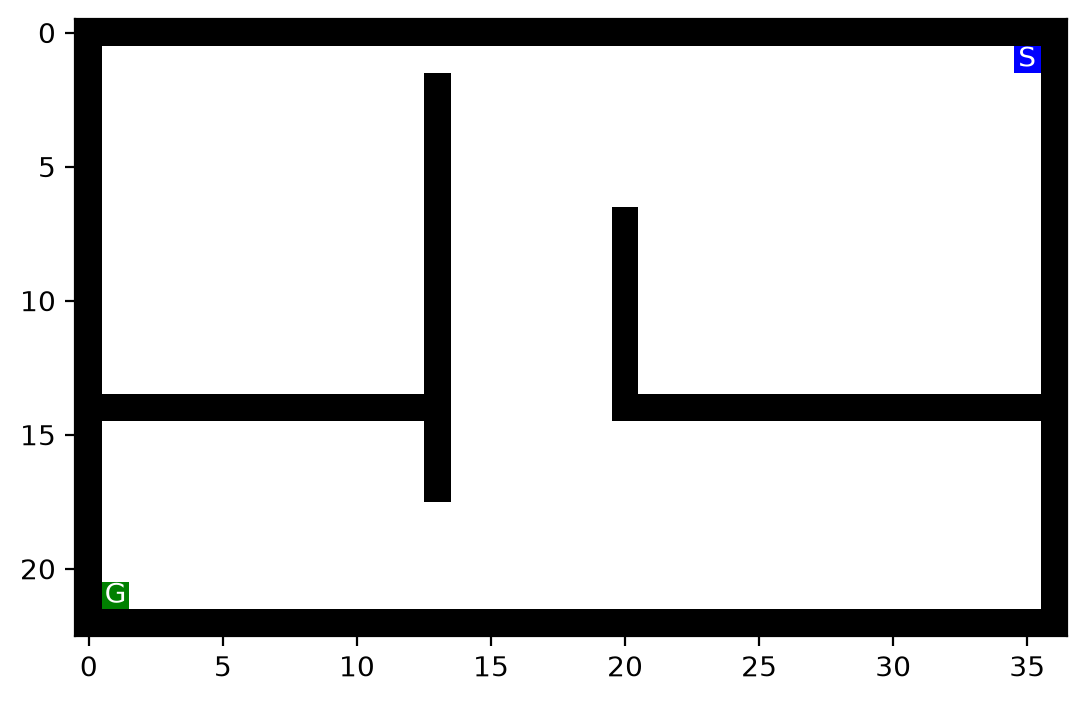

In [1]:
%run maze_helper.py
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

import numpy as np


#f = open("small_maze.txt", "r")
#f = open("medium_maze.txt", "r")
#f = open("large_maze.txt", "r")    # this has only one solution!
f = open("open_maze.txt", "r")
#f = open("empty_maze.txt", "r")
#f = open("empty_maze_2.txt", "r")
#f = open("loops_maze.txt", "r")
#f = open("L_maze.txt", "r")

maze_str = f.read()
maze = parse_maze(maze_str)

show_maze(maze)

**Cài đặt DFS dùng cho notebook này.** File `tree_search_solution.py` của tác giả không được phát hành, nên DFS với ba phương án kiểm tra chu trình được cài đặt lại ở đây (giữ nguyên tham số `frontier_option` như notebook gốc):

| `frontier_option` | Phương án | Cách xử lý khi sinh con có trạng thái $s$ |
|---|---|---|
| `3` | **PA1** – kiểm tra đường đi | Bỏ $s$ nếu $s$ nằm trên đường đi từ gốc tới nút hiện tại; ngược lại luôn đẩy vào stack (có thể trùng). |
| `2` | **PA2** – đường đi + không thêm trùng frontier | Như PA1, và bỏ $s$ nếu $s$ đang có trong frontier. |
| `1` | **PA3** – đường đi + đưa lên đỉnh stack | Như PA1; nếu $s$ đang có trong frontier thì xóa bản ghi cũ và đặt bản ghi mới lên đỉnh stack. |

DFS **không** dùng `reached`. Bảng `in_frontier` chỉ chứa các trạng thái *đang* nằm trong frontier (kích thước $O(bm)$), dùng cho PA2/PA3. Mỗi nút đếm số con còn sống; khi một nhánh không còn con nào trong frontier thì nhánh đó được giải phóng khỏi bộ nhớ (ô chuyển về màu trắng trong animation).

Màu trong animation: đỏ = nút đang nằm trong bộ nhớ (cây tìm kiếm hiện tại), cam = frontier, trắng = chưa thăm hoặc đã bị giải phóng.

In [2]:
import matplotlib.pyplot as plt
from collections import Counter

DIRECTIONS = {"N": (-1, 0), "E": (0, 1), "S": (1, 0), "W": (0, -1)}
order = list("NESW")


def set_order(new_order="NESW"):
    """Thứ tự đẩy các con vào stack (con cuối cùng được lấy ra trước)."""
    global order
    order = list(new_order)
    print("Directions are checked in the order", order)


class Node:
    def __init__(self, pos, parent, action, cost):
        self.pos = tuple(pos)
        self.parent = parent
        self.action = action
        self.cost = cost
        self.n_children = 0      # số con còn sống trong cây
        self.removed = False     # True: bản ghi frontier đã bị thay thế (PA3)

    def get_path_from_root(self):
        node, path = self, [self]
        while node.parent is not None:
            node = node.parent
            path.append(node)
        return path[::-1]


def on_path(node, pos):
    while node is not None:
        if node.pos == pos:
            return True
        node = node.parent
    return False


OPTION_NAMES = {3: "PA1: path", 2: "PA2: path + no duplicates", 1: "PA3: path + move to top"}


def DFS(maze, max_tries=500, frontier_option=1, animation=False, frame_every=5, vis=False):
    """DFS không reached với 3 phương án cycle checking (xem bảng ở trên)."""
    start = find_pos(maze, "S")
    start = (int(start[0]), int(start[1]))
    root = Node(start, None, None, 0)
    stack = [root]
    in_frontier = {start: root}
    counts = Counter({start: 1})        # số bản ghi hợp lệ của mỗi trạng thái trong frontier
    alive = 1
    expanded = reexpanded = 0
    explored = set()                    # chỉ để thống kê, thuật toán không đọc
    stats = {"max_frontier": 1, "max_duplicates": 0, "max_memory": 1}
    trace = {"frontier": [], "memory": []}
    frames = []

    def release(node):
        nonlocal alive
        while node is not None and node.n_children == 0:
            alive -= 1
            node = node.parent
            if node is not None:
                node.n_children -= 1

    def frame(current=None):
        m = np.copy(maze)
        live = [n for n in stack if not n.removed] + ([current] if current else [])
        seen = set()
        for n in live:
            while n is not None and id(n) not in seen:
                seen.add(id(n))
                if m[n.pos] == " ":
                    m[n.pos] = "P"
                n = n.parent
        for n in stack:
            if not n.removed and m[n.pos] in " P":
                m[n.pos] = "F"
        frames.append(m)

    def finish(goal_node, tries):
        res = {"path": None, "actions": None, "reached": [], "maze_anim": frames,
               "option": OPTION_NAMES[frontier_option], "tries": tries,
               "expanded": expanded, "distinct_expanded": len(explored),
               "reexpanded": reexpanded, "trace": trace, **stats}
        if goal_node is not None:
            nodes = goal_node.get_path_from_root()
            res["path"] = [n.pos for n in nodes]
            res["actions"] = [n.action for n in nodes[1:]]
            if animation:
                m = np.copy(maze)
                for p in res["path"]:
                    if m[p] == " ":
                        m[p] = "P"
                frames.append(m)
        return res

    tries = 0
    while stack:
        tries += 1
        if tries > max_tries:
            return finish(None, tries - 1)
        node = stack.pop()
        if node.removed:
            release(node)
            continue
        counts[node.pos] -= 1
        if in_frontier.get(node.pos) is node:
            del in_frontier[node.pos]

        if animation and tries % frame_every == 1:
            frame(node)
        if maze[node.pos] == "G":
            return finish(node, tries)

        expanded += 1
        reexpanded += node.pos in explored
        explored.add(node.pos)
        for a in order:
            dr, dc = DIRECTIONS[a]
            s = (node.pos[0] + dr, node.pos[1] + dc)
            if maze[s] == "X" or on_path(node, s):
                continue
            if s in in_frontier and frontier_option != 3:
                if frontier_option == 2:
                    continue
                old = in_frontier[s]          # frontier_option == 1
                old.removed = True
                counts[s] -= 1
            child = Node(s, node, a, node.cost + 1)
            node.n_children += 1
            alive += 1
            stack.append(child)
            in_frontier[s] = child
            counts[s] += 1
        if node.n_children == 0:
            release(node)

        live = sum(counts.values())
        distinct = sum(1 for v in counts.values() if v > 0)
        stats["max_frontier"] = max(stats["max_frontier"], live)
        stats["max_duplicates"] = max(stats["max_duplicates"], live - distinct)
        stats["max_memory"] = max(stats["max_memory"], alive)
        trace["frontier"].append(live)
        trace["memory"].append(alive)

    return finish(None, tries)


set_order("NESW")

Directions are checked in the order ['N', 'E', 'S', 'W']


## DFS Cycle checking option 1: Check the path

Do not expand nodes for states that are already in the current path. It works like this:

* Expand puts all new states into the frontier.
* When a state is taken from the frontier then we check if we already have a node for this state in the current path from the root node. If so,
then we ignore the state and pick the next one from the frontier. 
hen we try to add a frontier node to the current path then
we check if the state already exists in the path. 

Turns out that this does not manage the frontier well because there are cases where the same state gets added multiple times to the frontier leading to clearing 
space and then re-exploring it over and over again.


In [3]:
%time result = DFS(maze, max_tries=500, frontier_option=3, animation=True)

animate_maze(result)

CPU times: user 23.4 ms, sys: 0 ns, total: 23.4 ms
Wall time: 23.5 ms
No solution found.


The room looks solid red, but there are still some of the red points left in the frontier!

## DFS Cycle checking option 2: Check the path + don't add states that are already in the frontier a second time.

This unfortunately does not work and produces still an infinite loop if there are any open spaces in the maze!

In [4]:
%time result = DFS(maze, max_tries=500, frontier_option=2, animation=True)

animate_maze(result)

CPU times: user 17.6 ms, sys: 0 ns, total: 17.6 ms
Wall time: 17.5 ms
No solution found.


Note that there are still frontier entires (orange squares) left when DFS removed a completed branch from memory (squares that turn white). This is a problem, since DFS will explore them again leading to an infinite loop.



## DFS Cycle checking option 3: Check the path + fix the frontier by moving found states to the top of the frontier stack

Increasing the priority of a frontier entry when we see it again solves this issue (i.e., remove it from the stack and put it again on the top). 
Note that there are no orange squares left when DFS removes a path from memory so it knows that this part of the maze is done.

In [5]:
%time result = DFS(maze, max_tries=500, frontier_option=1, animation=True)

animate_maze(result)

CPU times: user 5.65 ms, sys: 48 μs, total: 5.7 ms
Wall time: 5.64 ms
Path length: 54
Reached squares: 0
Action sequence: ['W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'S', 'S', 'S']


# Bài 7 – So sánh ba phương án cycle checking

Chạy cả ba phương án trên `open_maze` với cùng thứ tự hướng `NESW`, ghi lại:

* **tries** – số lần lấy một bản ghi ra khỏi stack (số vòng lặp);
* **expanded / distinct / re-expanded** – số lần mở rộng, số ô khác nhau đã mở rộng và số lần mở rộng *lại* một ô đã mở rộng trước đó (hiện tượng lặp trạng thái);
* **max frontier** – số bản ghi hợp lệ lớn nhất trong stack; **max duplicates** – số bản ghi trùng trạng thái lớn nhất trong frontier;
* **max memory** – số nút lớn nhất cùng lúc trong cây tìm kiếm.

Thí nghiệm dùng hai mức `max_tries`: 500 (như animation) và 200 000 để xem PA1/PA2 có thoát ra được khi cho chạy lâu hơn hay không.

In [6]:
import pandas as pd


def summarize(res, max_tries):
    return {
        "option": res["option"], "max_tries": max_tries,
        "solved": res["path"] is not None,
        "path cost": len(res["path"]) - 1 if res["path"] else "N/A",
        "tries": res["tries"], "expanded": res["expanded"],
        "distinct": res["distinct_expanded"], "re-expanded": res["reexpanded"],
        "max frontier": res["max_frontier"], "max duplicates": res["max_duplicates"],
        "max memory": res["max_memory"],
    }


open_runs = {}
rows = []
for max_tries in [500, 200_000]:
    for opt in [3, 2, 1]:
        res = DFS(maze, max_tries=max_tries, frontier_option=opt)
        open_runs[(opt, max_tries)] = res
        rows.append(summarize(res, max_tries))
pd.DataFrame(rows).set_index(["max_tries", "option"])

solved path cost   tries  expanded  \
max_tries option                                                          
500       PA1: path                   False       N/A     500       500   
          PA2: path + no duplicates   False       N/A     500       500   
          PA3: path + move to top      True        54     344       211   
200000    PA1: path                   False       N/A  200000    200000   
          PA2: path + no duplicates   False       N/A  200000    200000   
          PA3: path + move to top      True        54     344       211   

                                     distinct  re-expanded  max frontier  \
max_tries option                                                           
500       PA1: path                       179          321           155   
          PA2: path + no duplicates       117          383            91   
          PA3: path + move to top         211            0            64   
200000    PA1: path                       179       199821           155   
          PA2: path + no duplicates       125       199875            93   
          PA3: path + move to top         211            0            64   

                                     max duplicates  max memory  
max_tries option                                                 
500       PA1: path                              17         333  
          PA2: path + no duplicates               0         201  
          PA3: path + move to top                 0         333  
200000    PA1: path                              24         333  
          PA2: path + no duplicates               0         201  
          PA3: path + move to top                 0         333

Diễn biến kích thước frontier và số nút trong bộ nhớ theo từng lần lặp (open maze, 2 000 lần lặp đầu):

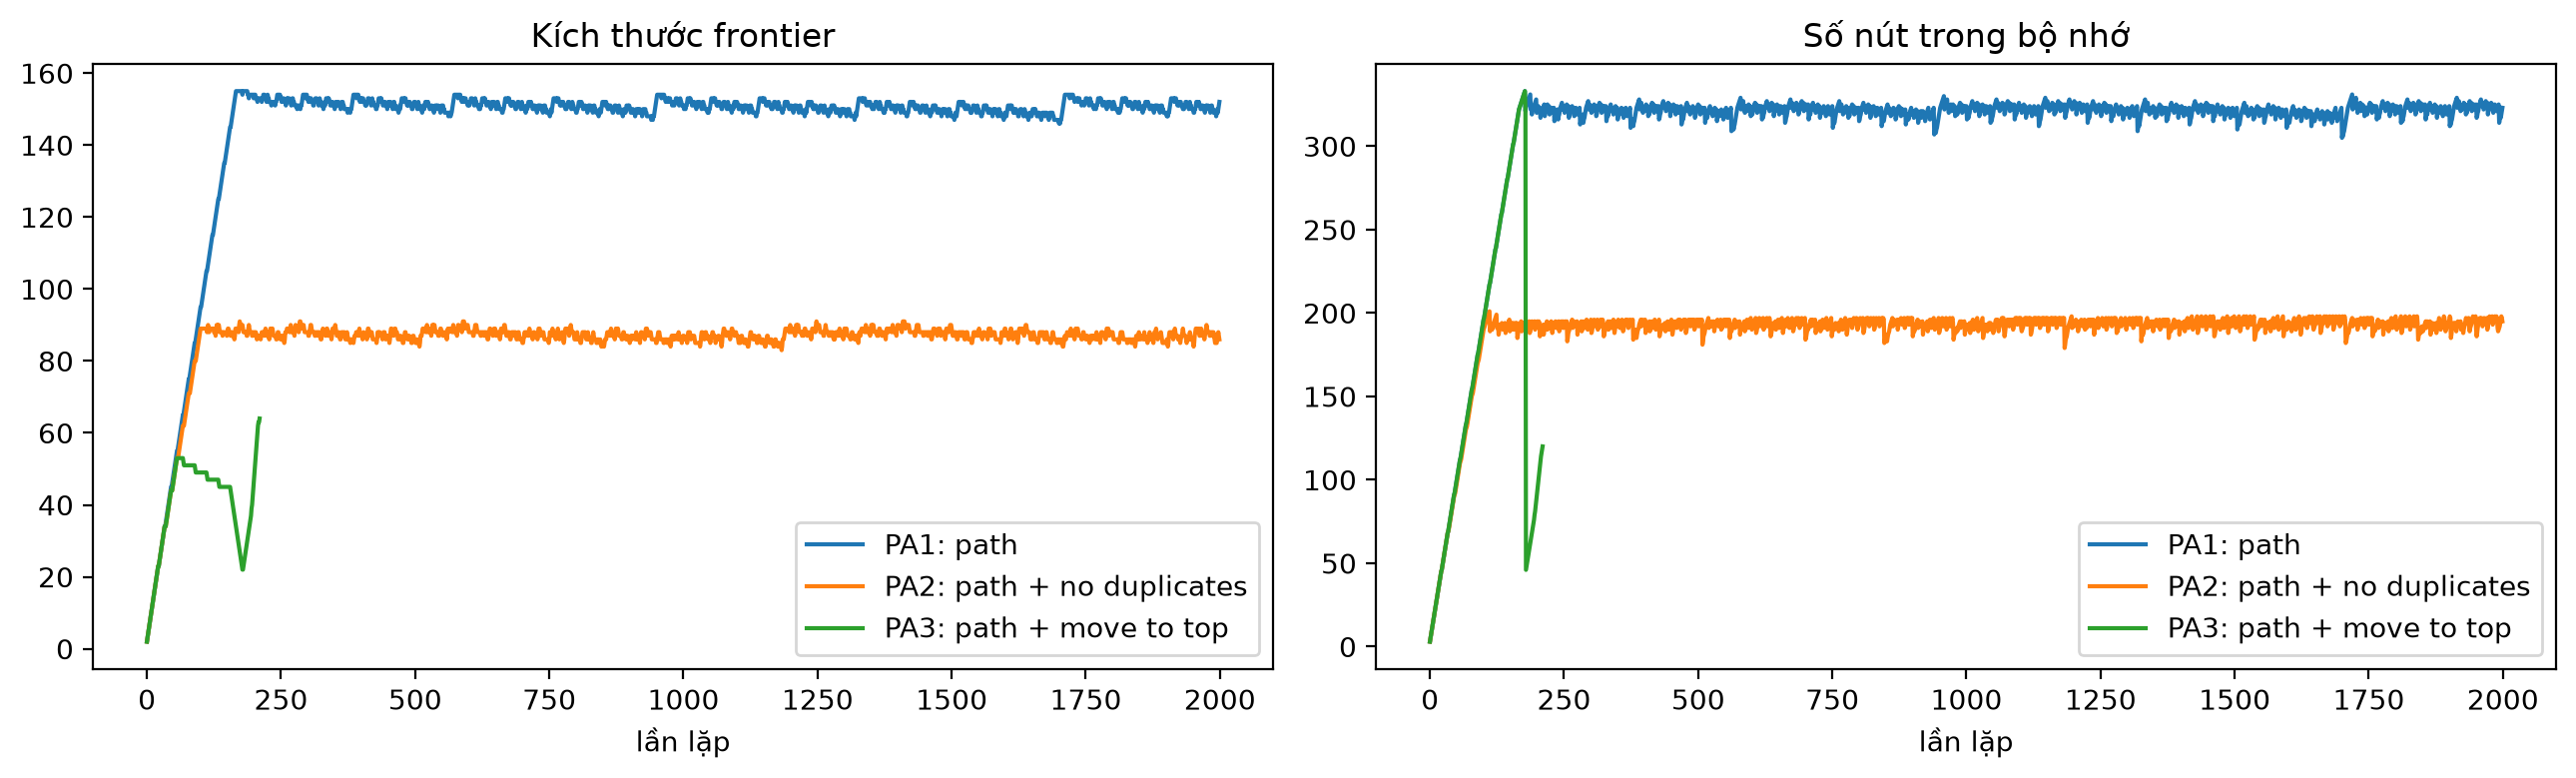

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for opt in [3, 2, 1]:
    res = open_runs[(opt, 200_000)]
    axes[0].plot(res["trace"]["frontier"][:2000], label=res["option"])
    axes[1].plot(res["trace"]["memory"][:2000], label=res["option"])
axes[0].set_title("Kích thước frontier")
axes[1].set_title("Số nút trong bộ nhớ")
for ax in axes:
    ax.set_xlabel("lần lặp")
    ax.legend()
plt.tight_layout()
plt.show()

Để thấy vấn đề chỉ xuất hiện ở vùng trống, chạy ba phương án trên tất cả mê cung (`max_tries = 200 000`):

In [8]:
maze_files = ["small_maze.txt", "medium_maze.txt", "large_maze.txt", "open_maze.txt",
              "L_maze.txt", "loops_maze.txt", "empty_maze.txt", "empty_maze_2.txt"]
rows = []
for file in maze_files:
    with open(file, "r") as f:
        m = parse_maze(f.read())
    for opt in [3, 2, 1]:
        res = DFS(m, max_tries=200_000, frontier_option=opt)
        rows.append({"maze": file.replace(".txt", ""), "option": res["option"],
                     "path cost": len(res["path"]) - 1 if res["path"] else "N/A",
                     "tries": res["tries"], "re-expanded": res["reexpanded"],
                     "max frontier": res["max_frontier"], "max memory": res["max_memory"]})
all_df = pd.DataFrame(rows)
all_df.pivot(index="maze", columns="option", values=["path cost", "tries", "re-expanded"])

path cost                                                    \
option       PA1: path PA2: path + no duplicates PA3: path + move to top   
maze                                                                       
L_maze             122                        80                     122   
empty_maze          80                        54                      80   
empty_maze_2        34                       N/A                      34   
large_maze         210                       210                     210   
loops_maze          27                        27                      27   
medium_maze        152                       152                     152   
open_maze          N/A                       N/A                      54   
small_maze          29                        29                      29   

                 tries                                                    \
option       PA1: path PA2: path + no duplicates PA3: path + move to top   
maze                                                                       
L_maze             133                        97                     133   
empty_maze          81                        71                      81   
empty_maze_2        35                    200000                      35   
large_maze         338                       338                     338   
loops_maze          31                        30                      31   
medium_maze        154                       154                     154   
open_maze       200000                    200000                     344   
small_maze          40                        40                      40   

             re-expanded                                                    
option         PA1: path PA2: path + no duplicates PA3: path + move to top  
maze                                                                        
L_maze                 0                         5                       0  
empty_maze             0                         7                       0  
empty_maze_2           0                    199933                       0  
large_maze             0                         0                       0  
loops_maze             0                         0                       0  
medium_maze            0                         0                       0  
open_maze         199821                    199875                       0  
small_maze             0                         0                       0

## Nhận xét Bài 7

**PA1 – chỉ kiểm tra đường đi.** Chặn được chu trình *trên một nhánh* nên về lý thuyết không lặp vô hạn (mỗi nhánh là một đường đơn) – nhưng không biết gì về các nhánh khác. Cùng một ô được đẩy vào stack nhiều lần từ các ô lân cận (cột `max duplicates`), và sau khi một nhánh được giải phóng, các ô đó lại được thăm theo một đường đơn khác. Trong căn phòng trống, số đường đơn tăng theo hàm mũ, nên DFS "tô kín" căn phòng (animation: phòng đỏ đặc) rồi quét đi quét lại: hàng trăm nghìn lần mở rộng lại (`re-expanded`) mà vẫn không ra khỏi phòng sau 200 000 lần lặp.

**PA2 – thêm điều kiện không thêm trạng thái đang có trong frontier.** Frontier gọn hơn (không có bản ghi trùng), nhưng bản ghi giữ lại là bản ghi *cũ*, thuộc một nhánh nông hơn. Khi DFS đi sâu xong nhánh hiện tại và giải phóng nó, các bản ghi cũ này (ô cam còn sót lại) vẫn ở dưới stack nên vùng vừa xóa lại bị khám phá lại từ đầu → vẫn lặp gần như vô hạn trên open maze (gần 200 000 lần mở rộng lại) và cả empty_maze_2. Ở L và empty maze PA2 lại tình cờ ra đường ngắn hơn (80 và 54 bước) nhưng đã phải mở rộng lại vài ô – hành vi phụ thuộc may rủi vào thứ tự các bản ghi cũ còn sót.

**PA3 – đưa trạng thái tìm thấy lên đỉnh stack.** Mỗi trạng thái chỉ có **một** bản ghi trong frontier, và đó luôn là bản ghi thuộc nhánh đang được đi sâu. Khi một nhánh được giải phóng thì không còn bản ghi nào của vùng đó trong frontier (không còn ô cam), nên DFS không quay lại vùng đã xong. Trên open maze PA3 giải được ngay (344 lần lặp, 211 lần mở rộng – mỗi ô đúng một lần, đường đi 54 bước) với frontier tối đa 64 bản ghi so với 155 của PA1. Bộ nhớ tối đa (333 nút) bằng PA1 vì vẫn phải giữ một đường đi rất sâu.

**So sánh.**

| Tiêu chí (open maze) | PA1 | PA2 | PA3 |
|---|---|---|---|
| Số lần lặp | vượt `max_tries` | vượt `max_tries` | ít (giải được) |
| Kích thước frontier | lớn nhất, có bản ghi trùng | nhỏ hơn, không trùng | không trùng, ổn định |
| Lặp trạng thái | rất nhiều | rất nhiều | không |
| Chi phí quản lý | $O(m)$ kiểm tra đường đi | + bảng băm `in_frontier` | + bảng băm + xóa lười bản ghi cũ trong stack |

Ở các mê cung còn lại, PA1 và PA3 cho kết quả giống hệt nhau: với mê cung dạng hành lang (small, medium, large, loops) gần như không có hai đường khác nhau tới cùng một ô, còn ở L/empty maze DFS chạm đích trước khi phải quay lui qua vùng trống. Vấn đề bộc lộ rõ ở open maze, nơi DFS phải quay lui ra khỏi một căn phòng lớn.

**Đánh đổi (câu hỏi 12 của đề).** Cycle checking làm giảm lặp trạng thái nhưng tăng chi phí quản lý: kiểm tra đường đi tốn $O(m)$ mỗi lần sinh con; PA2/PA3 cần thêm cấu trúc tra cứu frontier và (với PA3) xóa phần tử giữa stack – ở đây dùng *xóa lười* (đánh dấu `removed`, bỏ qua khi lấy ra), nên stack có thể chứa bản ghi chết và tốn thêm vòng lặp. Không cách nào trong số này loại được hoàn toàn đường đi dư thừa như `reached` của BFS; muốn vậy phải lưu toàn bộ trạng thái đã gặp và mất lợi thế bộ nhớ $O(bm)$ của DFS. PA3 còn có một nhược điểm: khi dùng với giới hạn độ sâu (IDS) nó có thể thay bản ghi nông bằng bản ghi sâu hơn giới hạn và bỏ sót lời giải (xem phần IDS trong Ex1_Maze.ipynb).